## 전략 노트북입니다

In [1]:
# 모듈 임포트 셀
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rcParams["font.family"] = "AppleGothic" # 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("../outputs", exist_ok=True)
MIN_GROUP = 100   # 세그먼트 비율을 볼 때 필요한 최소 기업 수

In [3]:
# 데이터 불러오기. pred_test는 model 노트북이 저장한 평가 데이터 예측 확률
df = pd.read_csv("../data/clean.csv", encoding="utf-8-sig")
pred = pd.read_csv("../outputs/pred_test.csv", index_col=0, encoding="utf-8-sig")
importance = pd.read_csv("../outputs/importance.csv", encoding="utf-8-sig")

# csv로 읽으면 순서가 사라져서 다시 지정
order = df.groupby("업력구간")["업력"].min().sort_values().index
df["업력구간"] = pd.Categorical(df["업력구간"], categories=order)
df["기업규모"] = pd.Categorical(df["기업규모"], categories=["소기업", "중기업", "중견기업", "대기업", "한시성중소기업"])
print(df.shape, pred.shape)
importance.head(5)

(13389, 60) (2678, 7)


,feature,importance,std
0,업력,0.040053,0.006489
1,기업규모,0.022756,0.005699
2,22년 부가가치율,0.021157,0.003553
3,매출성장률_20_22,0.009011,0.002331
4,업종대분류,0.006375,0.002120


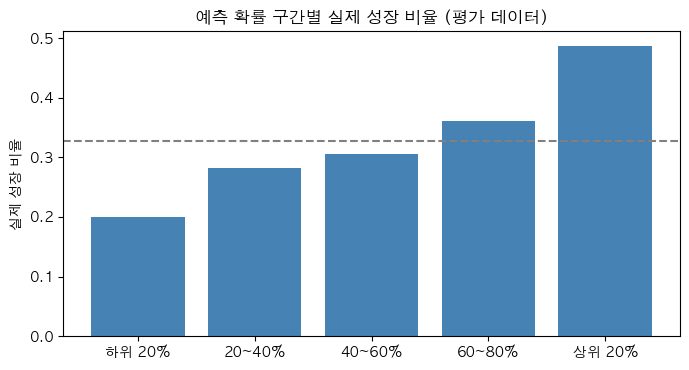

,mean,size,lift
확률구간,,,
하위 20%,0.200,536,0.610
20~40%,0.282,535,0.863
40~60%,0.306,536,0.935
60~80%,0.361,535,1.103
상위 20%,0.487,536,1.489


In [4]:
# 예측 확률 구간별 실제 성장 비율. 모델이 매긴 순위가 얼마나 믿을 만한지
pred["확률구간"] = pd.qcut(pred["prob_boost"], 5, labels=["하위 20%", "20~40%", "40~60%", "60~80%", "상위 20%"])
calib = pred.groupby("확률구간", observed=True)["성장여부"].agg(["mean", "size"])
calib["lift"] = calib["mean"] / pred["성장여부"].mean()

plt.figure(figsize=(7, 3.8))
plt.bar(calib.index.astype(str), calib["mean"], color="steelblue")
plt.axhline(pred["성장여부"].mean(), color="gray", linestyle="--")   # 전체 평균
plt.ylabel("실제 성장 비율")
plt.title("예측 확률 구간별 실제 성장 비율 (평가 데이터)")
plt.tight_layout()
plt.savefig("../outputs/strategy_calibration.png")
plt.show()
calib.round(3)

In [5]:
# 상위 20%와 하위 20% 기업의 특성 비교
cols = ["22년 부가가치율", "매출성장률_20_22", "22년 부채비율", "22년 총자산회전율", "22년 총자산"]
joined = pred.join(df[cols])   # 업력은 pred에 이미 있음
cols = ["업력"] + cols
top = joined[joined["확률구간"] == "상위 20%"]
bottom = joined[joined["확률구간"] == "하위 20%"]

compare = pd.DataFrame({"상위 20%": top[cols].median(), "하위 20%": bottom[cols].median()})
compare["실제 성장 비율"] = [top["성장여부"].mean(), bottom["성장여부"].mean()] + [np.nan] * (len(cols) - 2)
print("기업규모 비율")
print(pd.crosstab(joined["확률구간"], joined["기업규모"], normalize="index").loc[["상위 20%", "하위 20%"]].round(2))
compare.round(2)

기업규모 비율
기업규모     기타   소기업  중견기업   중기업  한시성중소기업
확률구간                                  
상위 20%  0.0  0.60  0.02  0.38      0.0
하위 20%  0.0  0.69  0.01  0.29      0.0


,상위 20%,하위 20%,실제 성장 비율
업력,7.00,18.00,0.49
22년 부가가치율,26.15,10.10,0.20
매출성장률_20_22,1.08,-0.12,NaN
22년 부채비율,2.13,1.00,NaN
22년 총자산회전율,0.87,0.51,NaN
22년 총자산,35.00,45.00,NaN


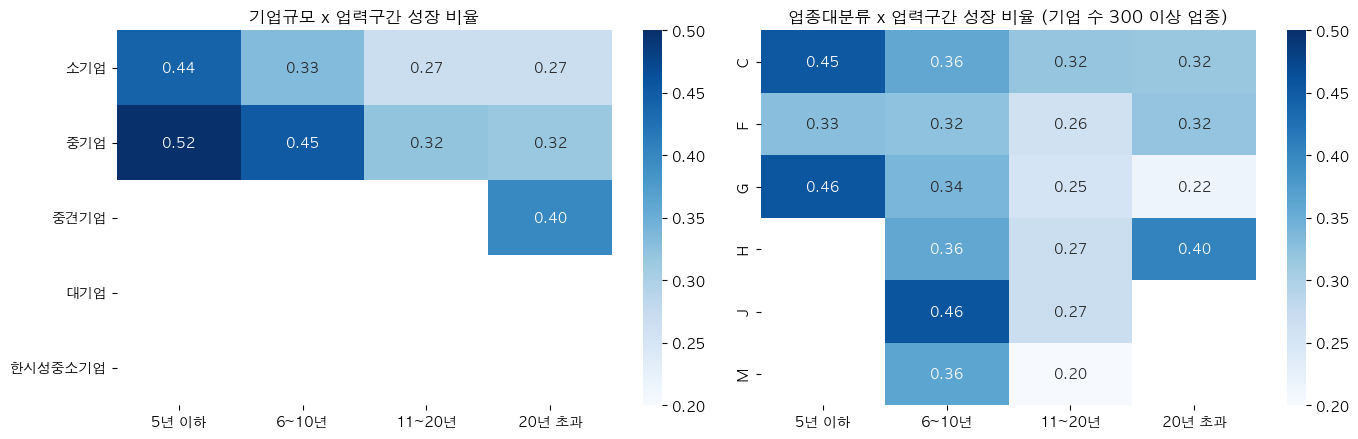

In [6]:
# 세그먼트별 성장 비율. 기업규모 x 업력구간, 업종대분류 x 업력구간
def segment_table(row, col):
    rate = df.pivot_table(index=row, columns=col, values="성장여부", aggfunc="mean", observed=True)
    size = df.pivot_table(index=row, columns=col, values="성장여부", aggfunc="size", observed=True)
    return rate.where(size >= MIN_GROUP)   # 기업 수 적은 칸은 비움

big_ind = df["업종대분류"].value_counts()
big_ind = big_ind[big_ind >= 300].index
sub = df[df["업종대분류"].isin(big_ind)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(segment_table("기업규모", "업력구간"), annot=True, fmt=".2f", cmap="Blues", vmin=0.2, vmax=0.5, ax=axes[0])
axes[0].set_title("기업규모 x 업력구간 성장 비율")
rate = sub.pivot_table(index="업종대분류", columns="업력구간", values="성장여부", aggfunc="mean", observed=True)
size = sub.pivot_table(index="업종대분류", columns="업력구간", values="성장여부", aggfunc="size", observed=True)
sns.heatmap(rate.where(size >= MIN_GROUP), annot=True, fmt=".2f", cmap="Blues", vmin=0.2, vmax=0.5, ax=axes[1])
axes[1].set_title("업종대분류 x 업력구간 성장 비율 (기업 수 300 이상 업종)")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../outputs/strategy_segment.png")
plt.show()

In [7]:
# 같은 업종 안에서 성장 기업이 갖는 공통 특성. 여 그룹 중앙값에서 부 그룹 중앙값을 뺀 값
cols = ["업력", "22년 부가가치율", "매출성장률_20_22", "22년 부채비율", "22년 총자산회전율"]
rows = []
for code in big_ind:
    part = df[df["업종대분류"] == code]
    med = part.groupby("성장여부")[cols].median()
    diff = med.loc[1] - med.loc[0]
    diff["업종대분류"] = code
    diff["기업 수"] = len(part)
    rows.append(diff)
within = pd.DataFrame(rows).set_index("업종대분류")
within.round(2)

,업력,22년 부가가치율,매출성장률_20_22,22년 부채비율,22년 총자산회전율,기업 수
업종대분류,,,,,,
C,-2.0,1.85,0.12,0.24,0.07,4992
G,-3.0,1.20,0.16,-0.22,0.00,4935
F,0.0,3.35,0.20,-0.12,0.07,1432
J,-4.0,2.70,0.09,0.00,0.08,487
H,0.0,15.10,0.03,1.02,0.26,446
M,-3.0,1.30,0.20,0.00,-0.01,344


In [8]:
# 제안용 후보군. 사전 지표만으로 고를 수 있는 단순 규칙
# 업력 10년 이하, 22년 부가가치율이 업종 중앙값 이상, 20년 대비 22년 매출이 늘어난 기업
ind_median = df.groupby("업종대분류")["22년 부가가치율"].transform("median")
rule = (df["업력"] <= 10) & (df["22년 부가가치율"] >= ind_median) & (df["매출성장률_20_22"] > 0)

summary = pd.DataFrame({
    "기업 수": [rule.sum(), (~rule).sum(), len(df)],
    "성장 비율": [df.loc[rule, "성장여부"].mean(), df.loc[~rule, "성장여부"].mean(), df["성장여부"].mean()],
}, index=["후보군", "나머지", "전체"])
summary["성장 비율"] = summary["성장 비율"].round(3)
summary.to_csv("../outputs/strategy_rule.csv", encoding="utf-8-sig")

# 후보군 안에서 규모별로 다시 확인
print(df[rule].groupby("기업규모", observed=True)["성장여부"].agg(["mean", "size"]).round(3))
summary

          mean  size
기업규모                
소기업      0.374  1634
중기업      0.542   262
대기업      1.000     1
한시성중소기업  1.000     2


,기업 수,성장 비율
후보군,1899,0.398
나머지,11490,0.315
전체,13389,0.327


In [9]:
# 규칙의 각 조건을 하나씩 뺐을 때 성장 비율이 어떻게 바뀌는지
conds = {
    "업력 10년 이하": df["업력"] <= 10,
    "부가가치율 업종 중앙값 이상": df["22년 부가가치율"] >= ind_median,
    "매출 20년 대비 22년 증가": df["매출성장률_20_22"] > 0,
}
rows = []
for name in conds:
    only = conds[name]
    rows.append({"조건": name + " 단독", "기업 수": only.sum(), "성장 비율": df.loc[only, "성장여부"].mean()})
rows.append({"조건": "세 조건 모두", "기업 수": rule.sum(), "성장 비율": df.loc[rule, "성장여부"].mean()})
pd.DataFrame(rows).round(3)

,조건,기업 수,성장 비율
0,업력 10년 이하 단독,5443,0.383
1,부가가치율 업종 중앙값 이상 단독,6689,0.356
2,매출 20년 대비 22년 증가 단독,8204,0.346
3,세 조건 모두,1899,0.398
